In [1]:
import sys

print(sys.executable)

D:\btech\sem - 5\MHRR\MHRR project\.venv\Scripts\python.exe


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nSetup successful!")

NumPy: 2.5.3
Pandas: 3.0.6
Scikit-learn: 1.9.1

Setup successful!


In [3]:
df = pd.read_csv("MI302_roof_fall_dataset.csv")

In [4]:
df.head()

,Mine_No,CMRR,PRSUP,Intersection_Span_ft,Depth_of_Cover_ft,Mining_Height_ft,RFR,Risk_Class
0,1,59,5.32,65.9,150,6.0,0.00,Low
1,1,59,5.32,65.9,150,6.0,0.00,Low
2,2,50,3.93,60.0,400,7.0,0.66,Moderate
3,2,50,5.90,60.0,400,7.0,1.08,Moderate
4,2,75,3.93,60.0,400,7.0,0.00,Low


In [5]:
df.shape

(109, 8)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 109 entries, 0 to 108
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Mine_No               109 non-null    int64  
 1   CMRR                  109 non-null    int64  
 2   PRSUP                 109 non-null    float64
 3   Intersection_Span_ft  109 non-null    float64
 4   Depth_of_Cover_ft     109 non-null    int64  
 5   Mining_Height_ft      109 non-null    float64
 6   RFR                   109 non-null    float64
 7   Risk_Class            109 non-null    str    
dtypes: float64(4), int64(3), str(1)
memory usage: 6.9 KB


In [7]:
df.dtypes

Mine_No                   int64
CMRR                      int64
PRSUP                   float64
Intersection_Span_ft    float64
Depth_of_Cover_ft         int64
Mining_Height_ft        float64
RFR                     float64
Risk_Class                  str
dtype: object

In [8]:
df.isnull().sum()

Mine_No                 0
CMRR                    0
PRSUP                   0
Intersection_Span_ft    0
Depth_of_Cover_ft       0
Mining_Height_ft        0
RFR                     0
Risk_Class              0
dtype: int64

In [9]:
df[df.duplicated()]

,Mine_No,CMRR,PRSUP,Intersection_Span_ft,Depth_of_Cover_ft,Mining_Height_ft,RFR,Risk_Class
1,1,59,5.32,65.9,150,6.0,0.0,Low
68,22,40,5.90,63.0,400,7.0,0.0,Low
85,29,35,6.00,64.0,200,7.5,0.0,Low


In [10]:
df.duplicated().sum()

np.int64(3)

In [11]:
df[df.duplicated(keep=False)]

,Mine_No,CMRR,PRSUP,Intersection_Span_ft,Depth_of_Cover_ft,Mining_Height_ft,RFR,Risk_Class
0,1,59,5.32,65.9,150,6.0,0.0,Low
1,1,59,5.32,65.9,150,6.0,0.0,Low
67,22,40,5.90,63.0,400,7.0,0.0,Low
68,22,40,5.90,63.0,400,7.0,0.0,Low
84,29,35,6.00,64.0,200,7.5,0.0,Low
85,29,35,6.00,64.0,200,7.5,0.0,Low


In [12]:
df.describe()

,Mine_No,CMRR,PRSUP,Intersection_Span_ft,Depth_of_Cover_ft,Mining_Height_ft,RFR
count,109.000000,109.000000,109.000000,109.000000,109.000000,109.000000,109.000000
mean,19.055046,47.724771,5.711009,63.447706,448.853211,6.288991,2.751101
std,10.613439,11.104613,2.286372,5.607594,223.202318,1.942523,5.251673
min,1.000000,28.000000,2.460000,50.000000,150.000000,3.000000,0.000000
25%,11.000000,40.000000,3.980000,60.000000,300.000000,5.000000,0.000000
50%,19.000000,45.000000,5.320000,63.000000,400.000000,6.500000,0.520000
75%,27.000000,53.000000,6.830000,66.300000,500.000000,7.500000,3.150000
max,37.000000,78.000000,14.670000,78.400000,1100.000000,10.000000,31.820000


In [13]:
features = [
    "CMRR",
    "PRSUP",
    "Intersection_Span_ft",
    "Depth_of_Cover_ft",
    "Mining_Height_ft"
]

df[features].describe()

,CMRR,PRSUP,Intersection_Span_ft,Depth_of_Cover_ft,Mining_Height_ft
count,109.000000,109.000000,109.000000,109.000000,109.000000
mean,47.724771,5.711009,63.447706,448.853211,6.288991
std,11.104613,2.286372,5.607594,223.202318,1.942523
min,28.000000,2.460000,50.000000,150.000000,3.000000
25%,40.000000,3.980000,60.000000,300.000000,5.000000
50%,45.000000,5.320000,63.000000,400.000000,6.500000
75%,53.000000,6.830000,66.300000,500.000000,7.500000
max,78.000000,14.670000,78.400000,1100.000000,10.000000


In [14]:
df["Risk_Class"].value_counts()

Risk_Class
Low         52
High        39
Moderate    18
Name: count, dtype: int64

In [15]:
df["Risk_Class"].value_counts(normalize=True) * 100

Risk_Class
Low         47.706422
High        35.779817
Moderate    16.513761
Name: proportion, dtype: float64

# Distribution of Roof Fall Risk Classes

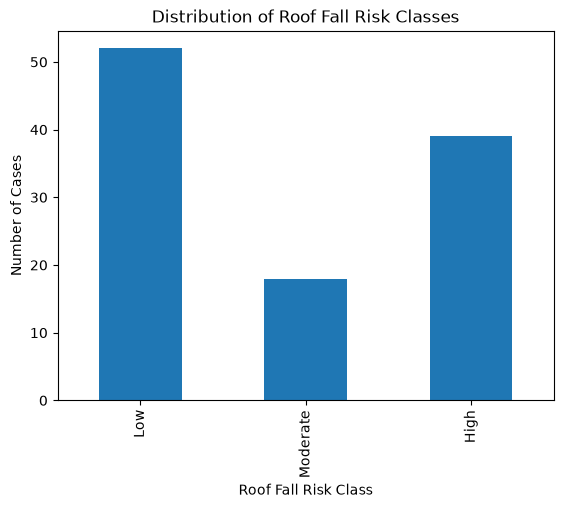

In [16]:
class_counts = df["Risk_Class"].value_counts().reindex(
    ["Low", "Moderate", "High"]
)

class_counts.plot(kind="bar")

plt.xlabel("Roof Fall Risk Class")
plt.ylabel("Number of Cases")
plt.title("Distribution of Roof Fall Risk Classes")
plt.xticks()

plt.show()

# Distribution of Roof Fall Rate(RFR)

In [17]:
df["RFR"].describe()

count    109.000000
mean       2.751101
std        5.251673
min        0.000000
25%        0.000000
50%        0.520000
75%        3.150000
max       31.820000
Name: RFR, dtype: float64

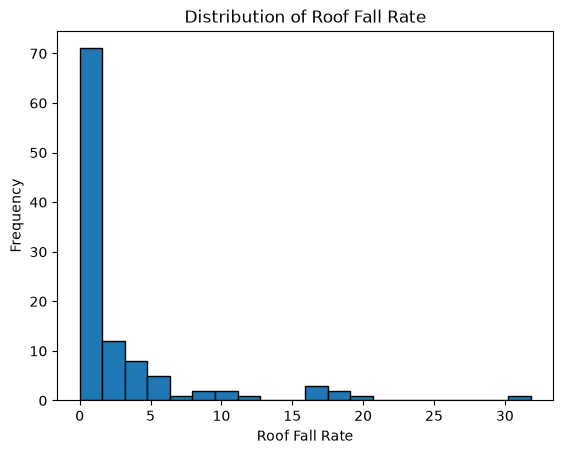

In [18]:
plt.hist(df["RFR"], bins=20, edgecolor="black")

plt.xlabel("Roof Fall Rate")
plt.ylabel("Frequency")
plt.title("Distribution of Roof Fall Rate")

plt.show()

In [19]:
df.sort_values("RFR", ascending=False)[
    ["Mine_No", "RFR", "Risk_Class"]
].head(10)

,Mine_No,RFR,Risk_Class
99,35,31.82,High
79,27,20.00,High
73,24,18.27,High
59,21,17.86,High
62,21,17.18,High
80,27,16.67,High
82,27,15.91,High
38,15,12.07,High
76,26,10.53,High
52,19,10.42,High


# Distribution of Coal Mine Roof Rating(CMRR)

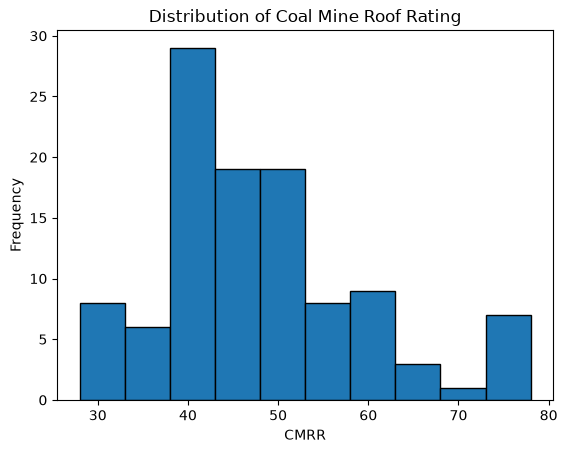

In [20]:
plt.hist(df["CMRR"], bins=10, edgecolor="black")

plt.xlabel("CMRR")
plt.ylabel("Frequency")
plt.title("Distribution of Coal Mine Roof Rating")

plt.show()

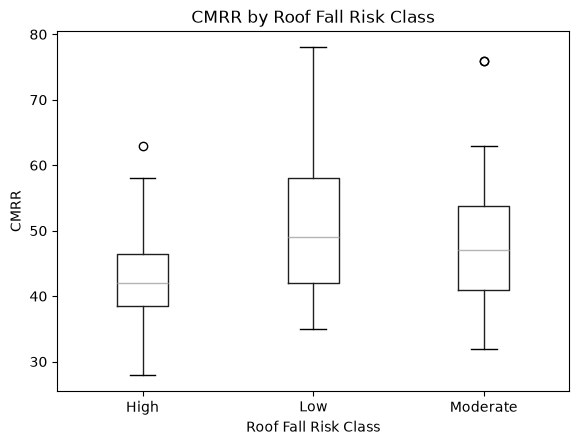

In [21]:
df.boxplot(
    column="CMRR",
    by="Risk_Class",
    grid=False
)

plt.xlabel("Roof Fall Risk Class")
plt.ylabel("CMRR")
plt.title("CMRR by Roof Fall Risk Class")
plt.suptitle("")

plt.show()

In [22]:
df.groupby("Risk_Class")["CMRR"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
Risk_Class,,,,,,
High,39,42.384615,42.0,8.177683,28,63
Low,52,51.192308,49.0,11.184791,35,78
Moderate,18,49.277778,47.0,12.404011,32,76


# Distribution of Primary Roof Support Index

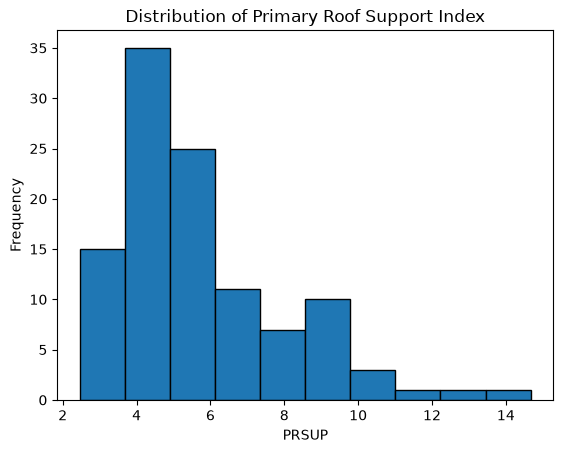

In [23]:
plt.hist(df["PRSUP"], bins=10, edgecolor="black")

plt.xlabel("PRSUP")
plt.ylabel("Frequency")
plt.title("Distribution of Primary Roof Support Index")

plt.show()

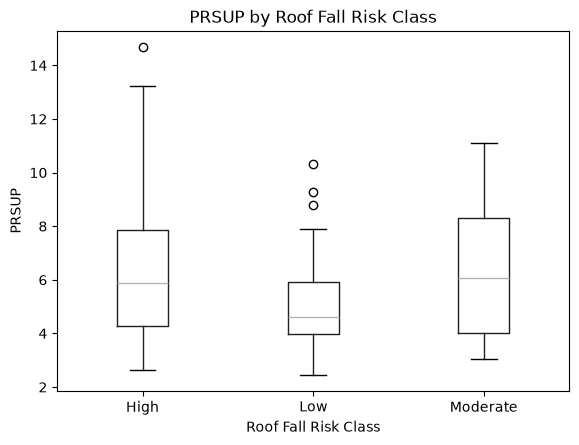

In [24]:
df.boxplot(
    column="PRSUP",
    by="Risk_Class",
    grid=False
)

plt.xlabel("Roof Fall Risk Class")
plt.ylabel("PRSUP")
plt.title("PRSUP by Roof Fall Risk Class")
plt.suptitle("")

plt.show()

In [25]:
df.groupby("Risk_Class")["PRSUP"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
Risk_Class,,,,,,
High,39,6.361282,5.890,2.714305,2.62,14.67
Low,52,5.017115,4.595,1.673353,2.46,10.31
Moderate,18,6.306667,6.075,2.350039,3.03,11.10


# Distribution of Intersection Diagonal Span

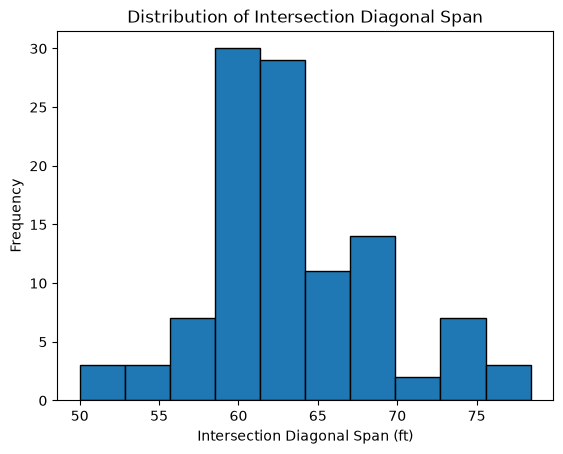

In [26]:
plt.hist(
    df["Intersection_Span_ft"],
    bins=10,
    edgecolor="black"
)

plt.xlabel("Intersection Diagonal Span (ft)")
plt.ylabel("Frequency")
plt.title("Distribution of Intersection Diagonal Span")

plt.show()

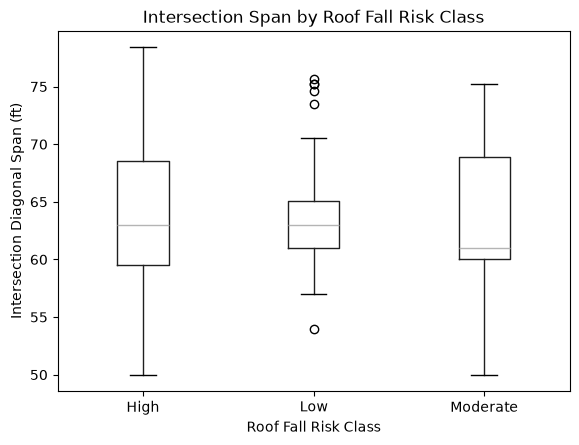

In [27]:
df.boxplot(
    column="Intersection_Span_ft",
    by="Risk_Class",
    grid=False
)

plt.xlabel("Roof Fall Risk Class")
plt.ylabel("Intersection Diagonal Span (ft)")
plt.title("Intersection Span by Roof Fall Risk Class")
plt.suptitle("")

plt.show()

In [28]:
df.groupby("Risk_Class")["Intersection_Span_ft"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
Risk_Class,,,,,,
High,39,63.387179,63.0,6.495107,50.0,78.4
Low,52,63.728846,63.0,4.705372,54.0,75.7
Moderate,18,62.766667,61.0,6.189270,50.0,75.2


# Distribution of Depth of Cover

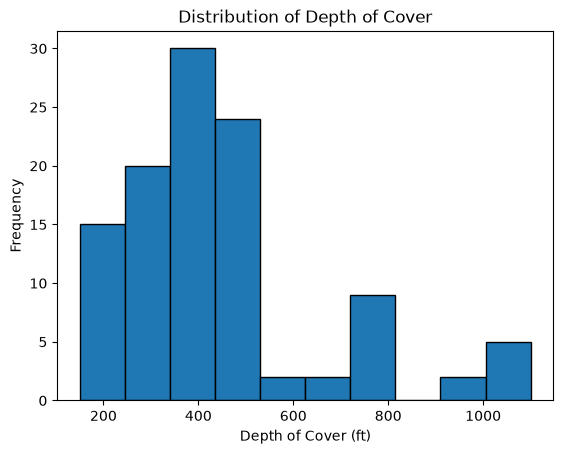

In [29]:
plt.hist(
    df["Depth_of_Cover_ft"],
    bins=10,
    edgecolor="black"
)

plt.xlabel("Depth of Cover (ft)")
plt.ylabel("Frequency")
plt.title("Distribution of Depth of Cover")

plt.show()

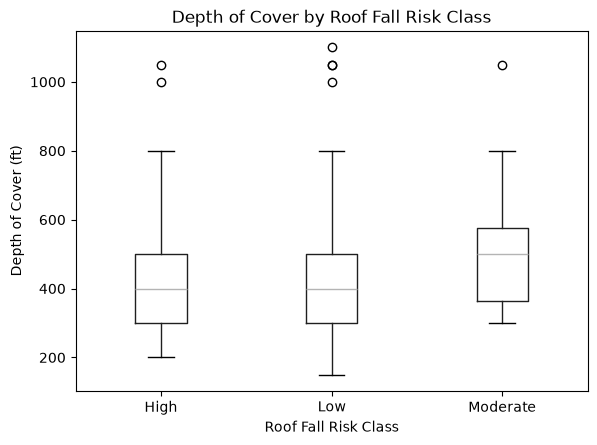

In [30]:
df.boxplot(
    column="Depth_of_Cover_ft",
    by="Risk_Class",
    grid=False
)

plt.xlabel("Roof Fall Risk Class")
plt.ylabel("Depth of Cover (ft)")
plt.title("Depth of Cover by Roof Fall Risk Class")
plt.suptitle("")

plt.show()

In [31]:
df.groupby("Risk_Class")["Depth_of_Cover_ft"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
Risk_Class,,,,,,
High,39,435.897436,400.0,199.324094,200,1050
Low,52,436.057692,400.0,246.962600,150,1100
Moderate,18,513.888889,500.0,198.379876,300,1050


# Distribution of Mining Height

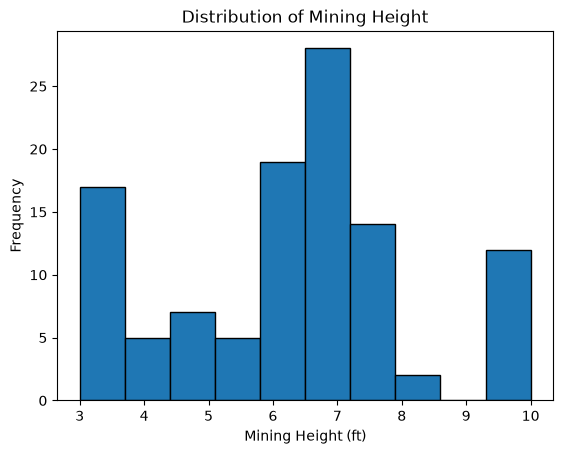

In [32]:
plt.hist(
    df["Mining_Height_ft"],
    bins=10,
    edgecolor="black"
)

plt.xlabel("Mining Height (ft)")
plt.ylabel("Frequency")
plt.title("Distribution of Mining Height")

plt.show()

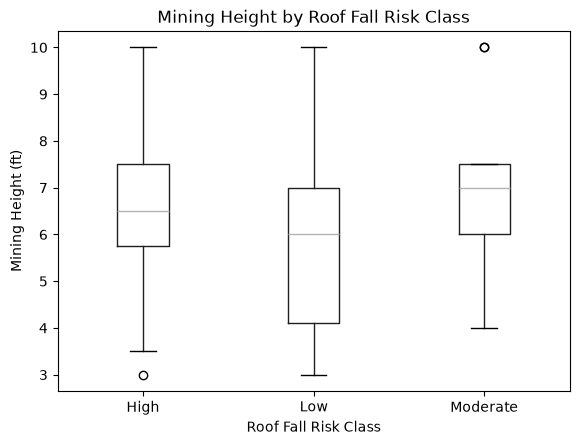

In [33]:
df.boxplot(
    column="Mining_Height_ft",
    by="Risk_Class",
    grid=False
)

plt.xlabel("Roof Fall Risk Class")
plt.ylabel("Mining Height (ft)")
plt.title("Mining Height by Roof Fall Risk Class")
plt.suptitle("")

plt.show()

In [34]:
df.groupby("Risk_Class")["Mining_Height_ft"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
Risk_Class,,,,,,
High,39,6.687179,6.5,1.974999,3.0,10.0
Low,52,5.830769,6.0,1.954135,3.0,10.0
Moderate,18,6.750000,7.0,1.601929,4.0,10.0


# feature summary

In [35]:
df.groupby("Risk_Class")[features].mean().round(2)

,CMRR,PRSUP,Intersection_Span_ft,Depth_of_Cover_ft,Mining_Height_ft
Risk_Class,,,,,
High,42.38,6.36,63.39,435.90,6.69
Low,51.19,5.02,63.73,436.06,5.83
Moderate,49.28,6.31,62.77,513.89,6.75


In [36]:
df.groupby("Risk_Class")[features].median().round(2)

,CMRR,PRSUP,Intersection_Span_ft,Depth_of_Cover_ft,Mining_Height_ft
Risk_Class,,,,,
High,42.0,5.89,63.0,400.0,6.5
Low,49.0,4.60,63.0,400.0,6.0
Moderate,47.0,6.08,61.0,500.0,7.0


# Correlation matrix

In [37]:
correlation_matrix = df[
    features + ["RFR"]
].corr()

correlation_matrix.round(2)

,CMRR,PRSUP,Intersection_Span_ft,Depth_of_Cover_ft,Mining_Height_ft,RFR
CMRR,1.00,-0.28,0.23,0.22,0.00,-0.21
PRSUP,-0.28,1.00,-0.05,0.18,0.41,0.27
Intersection_Span_ft,0.23,-0.05,1.00,0.54,0.17,-0.05
Depth_of_Cover_ft,0.22,0.18,0.54,1.00,0.34,-0.02
Mining_Height_ft,0.00,0.41,0.17,0.34,1.00,0.06
RFR,-0.21,0.27,-0.05,-0.02,0.06,1.00


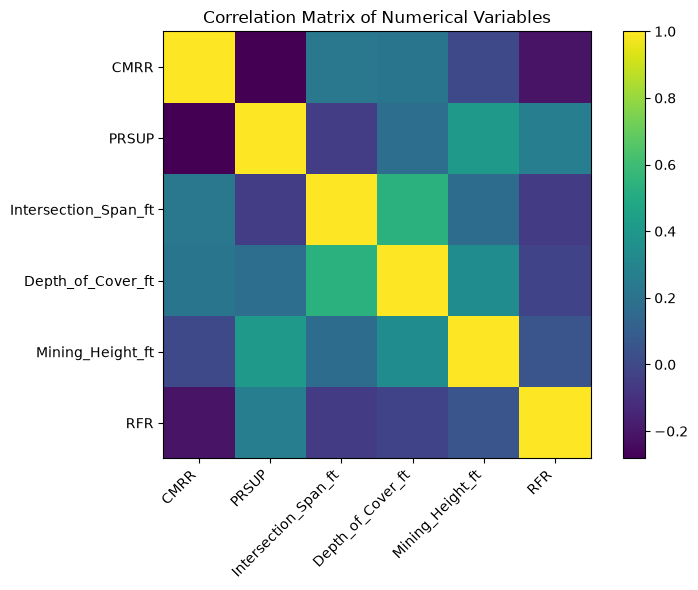

In [38]:
fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(correlation_matrix)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.columns)))

ax.set_xticklabels(
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(correlation_matrix.columns)

plt.colorbar(im)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()

plt.show()

# Preprocessing for Random Forest

### ML dataset

In [39]:
X = df[
    [
        "CMRR",
        "PRSUP",
        "Intersection_Span_ft",
        "Depth_of_Cover_ft",
        "Mining_Height_ft"
    ]
]

y = df["Risk_Class"]

In [40]:
X.head()

,CMRR,PRSUP,Intersection_Span_ft,Depth_of_Cover_ft,Mining_Height_ft
0,59,5.32,65.9,150,6.0
1,59,5.32,65.9,150,6.0
2,50,3.93,60.0,400,7.0
3,50,5.90,60.0,400,7.0
4,75,3.93,60.0,400,7.0


In [41]:
y.head()

0         Low
1         Low
2    Moderate
3    Moderate
4         Low
Name: Risk_Class, dtype: str

In [42]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (109, 5)
y shape: (109,)


### Train/test split

In [43]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y) 

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining classes:")
print(y_train.value_counts())

print("\nTesting classes:")
print(y_test.value_counts())

Training samples: 87
Testing samples: 22

Training classes:
Risk_Class
Low         42
High        31
Moderate    14
Name: count, dtype: int64

Testing classes:
Risk_Class
Low         10
High         8
Moderate     4
Name: count, dtype: int64


### Baseline Random Forest classifier

In [44]:
from sklearn.ensemble import RandomForestClassifier

In [45]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

### Train the Random Forest

In [46]:
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

### Make predictions

In [47]:
y_pred = rf_model.predict(X_test)

print("Actual:")
print(y_test.to_numpy())

print("\nPredicted:")
print(y_pred)

Actual:
['Low' 'Moderate' 'Low' 'Moderate' 'Low' 'High' 'High' 'Low' 'Low'
 'Moderate' 'Low' 'Low' 'High' 'Low' 'High' 'High' 'High' 'High' 'High'
 'Low' 'Moderate' 'Low']

Predicted:
['Low' 'Moderate' 'Low' 'High' 'Low' 'Moderate' 'Low' 'Low' 'Low' 'High'
 'Low' 'High' 'Low' 'High' 'High' 'High' 'Moderate' 'High' 'Moderate'
 'Low' 'Low' 'Low']


### First metric: accuracy

In [48]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy)

Test Accuracy: 0.5454545454545454


### Classification report

In [49]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

        High       0.43      0.38      0.40         8
         Low       0.73      0.80      0.76        10
    Moderate       0.25      0.25      0.25         4

    accuracy                           0.55        22
   macro avg       0.47      0.48      0.47        22
weighted avg       0.53      0.55      0.54        22



### Confusion matrix

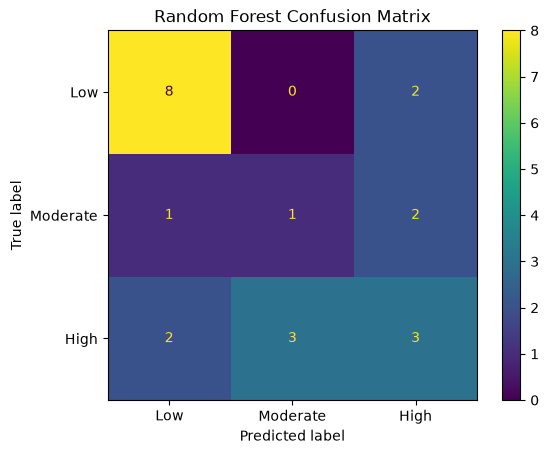

In [50]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Low", "Moderate", "High"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Moderate", "High"]
)

disp.plot()

plt.title("Random Forest Confusion Matrix")
plt.show()

### checking training performance

In [51]:
y_train_pred = rf_model.predict(X_train)

train_accuracy = accuracy_score(
    y_train,
    y_train_pred
)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", accuracy)

Training Accuracy: 0.9885057471264368
Testing Accuracy: 0.5454545454545454


In [52]:
print(
    classification_report(
        y_train,
        y_train_pred
    )
)

              precision    recall  f1-score   support

        High       1.00      0.97      0.98        31
         Low       0.98      1.00      0.99        42
    Moderate       1.00      1.00      1.00        14

    accuracy                           0.99        87
   macro avg       0.99      0.99      0.99        87
weighted avg       0.99      0.99      0.99        87



### Cross-validation

In [53]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print("F1 scores:", cv_scores)
print("Mean CV F1:", cv_scores.mean())
print("Std CV F1:", cv_scores.std())

F1 scores: [0.50992063 0.36521739 0.27407407 0.38909774 0.37608225]
Mean CV F1: 0.382878419148442
Std CV F1: 0.07533244972302795


### Tune the forest

In [54]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    "n_estimators": [100, 200, 300],

    "max_depth": [3, 5, 7, None],

    "min_samples_split": [2, 5, 10],

    "min_samples_leaf": [1, 2, 4],

    "max_features": ["sqrt", "log2"],

    "class_weight": [None, "balanced"]
}

rf_tuning = RandomForestClassifier(
    random_state=42
)

grid_search = GridSearchCV(
    estimator=rf_tuning,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(grid_search.best_score_)

Fitting 5 folds for each of 432 candidates, totalling 2160 fits
Best Parameters:
{'class_weight': 'balanced', 'max_depth': 7, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}

Best Cross-Validation Macro F1:
0.5149026028437793


### Retrieve the best model

In [55]:
best_rf = grid_search.best_estimator_

best_rf

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",7
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 T

### Check tuned training accuracy

In [56]:
best_train_pred = best_rf.predict(X_train)

best_train_accuracy = accuracy_score(
    y_train,
    best_train_pred
)

print("Tuned Training Accuracy:", best_train_accuracy)

Tuned Training Accuracy: 0.8620689655172413


### final test prediction

In [57]:
best_y_pred = best_rf.predict(X_test)
best_test_accuracy = accuracy_score(
    y_test,
    best_y_pred
)

print("Tuned Test Accuracy:", best_test_accuracy)

Tuned Test Accuracy: 0.5454545454545454


### Classification report

In [58]:
print(
    classification_report(
        y_test,
        best_y_pred
    )
)

              precision    recall  f1-score   support

        High       0.50      0.50      0.50         8
         Low       1.00      0.60      0.75        10
    Moderate       0.25      0.50      0.33         4

    accuracy                           0.55        22
   macro avg       0.58      0.53      0.53        22
weighted avg       0.68      0.55      0.58        22



### Calculate test Macro F1 explicitly

In [59]:
from sklearn.metrics import f1_score
best_macro_f1 = f1_score(
    y_test,
    best_y_pred,
    average="macro"
)

print("Tuned Test Macro F1:", best_macro_f1)

Tuned Test Macro F1: 0.5277777777777778


### Tuned confusion matrix

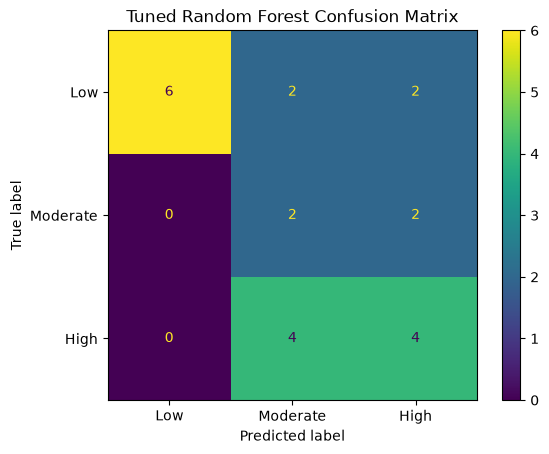

In [60]:
best_cm = confusion_matrix(
    y_test,
    best_y_pred,
    labels=["Low", "Moderate", "High"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=best_cm,
    display_labels=["Low", "Moderate", "High"]
)

disp.plot()

plt.title("Tuned Random Forest Confusion Matrix")
plt.show()

### Create a proper baseline-vs-tuned comparison

In [61]:
baseline_macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("BASELINE RANDOM FOREST")
print("----------------------")
print("Training Accuracy:", train_accuracy)
print("Test Accuracy:", accuracy)
print("Test Macro F1:", baseline_macro_f1)

print("\nTUNED RANDOM FOREST")
print("-------------------")
print("Training Accuracy:", best_train_accuracy)
print("Test Accuracy:", best_test_accuracy)
print("Test Macro F1:", best_macro_f1)

BASELINE RANDOM FOREST
----------------------
Training Accuracy: 0.9885057471264368
Test Accuracy: 0.5454545454545454
Test Macro F1: 0.4706349206349206

TUNED RANDOM FOREST
-------------------
Training Accuracy: 0.8620689655172413
Test Accuracy: 0.5454545454545454
Test Macro F1: 0.5277777777777778


### Feature Importance

In [62]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
0,CMRR,0.260781
1,PRSUP,0.241241
2,Intersection_Span_ft,0.194855
4,Mining_Height_ft,0.152093
3,Depth_of_Cover_ft,0.151031


In [63]:
feature_importance["Importance"].sum()

np.float64(1.0)

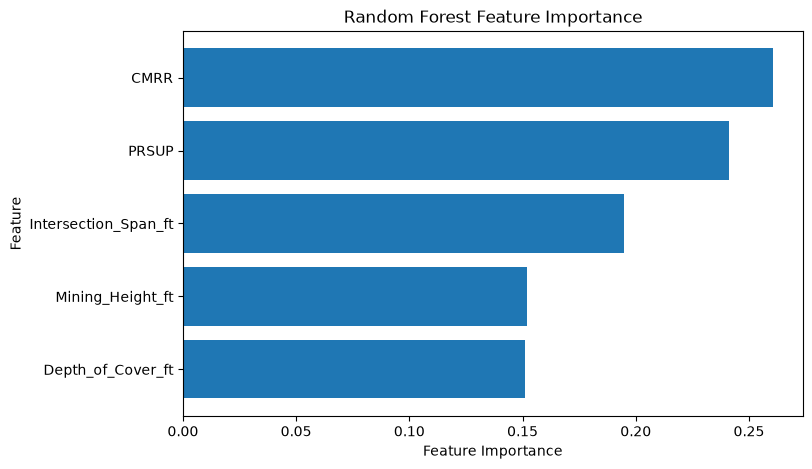

In [64]:
plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.show()

### Permutation Importance

In [65]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    best_rf,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=30,
    random_state=42
)

In [66]:
perm_importance = pd.DataFrame({
    "Feature": X.columns,
    "Mean_Importance": perm_result.importances_mean,
    "Std_Importance": perm_result.importances_std
})

perm_importance = perm_importance.sort_values(
    "Mean_Importance",
    ascending=False
)

perm_importance

,Feature,Mean_Importance,Std_Importance
0,CMRR,0.132187,0.084182
2,Intersection_Span_ft,0.049782,0.071579
4,Mining_Height_ft,0.030109,0.058693
3,Depth_of_Cover_ft,0.025957,0.055069
1,PRSUP,0.022723,0.043914


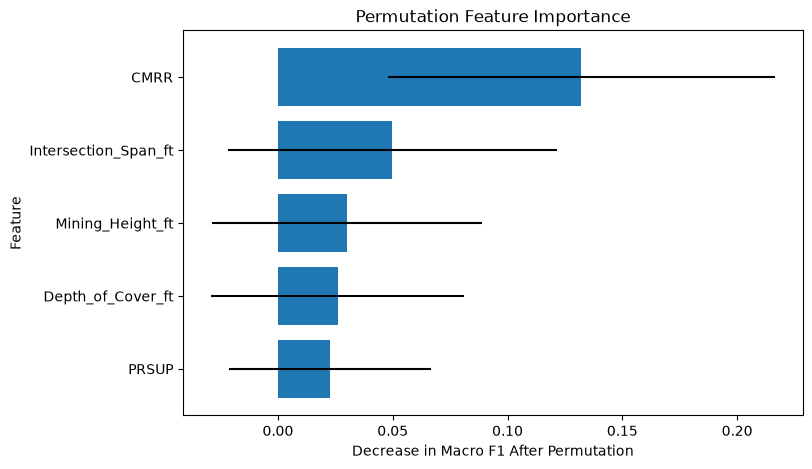

In [67]:
plt.figure(figsize=(8, 5))

plt.barh(
    perm_importance["Feature"],
    perm_importance["Mean_Importance"],
    xerr=perm_importance["Std_Importance"]
)

plt.xlabel("Decrease in Macro F1 After Permutation")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance")

plt.gca().invert_yaxis()

plt.show()

### make the model usable

In [68]:
MODEL_FEATURES = [
    "CMRR",
    "PRSUP",
    "Intersection_Span_ft",
    "Depth_of_Cover_ft",
    "Mining_Height_ft"
]

def predict_roof_fall_risk(
    cmrr,
    prsup,
    intersection_span,
    depth_of_cover,
    mining_height
):

    input_data = pd.DataFrame(
        [[
            cmrr,
            prsup,
            intersection_span,
            depth_of_cover,
            mining_height
        ]],
        columns=MODEL_FEATURES
    )

    predicted_class = best_rf.predict(input_data)[0]

    probabilities = best_rf.predict_proba(input_data)[0]

    print(f"Predicted Roof Fall Risk: {predicted_class}")
    print("\nModel Class Probabilities:")

    for risk_class, probability in zip(
        best_rf.classes_,
        probabilities
    ):
        print(f"{risk_class}: {probability * 100:.2f}%")

In [69]:
predict_roof_fall_risk(
    cmrr=40,
    prsup=6.0,
    intersection_span=65,
    depth_of_cover=500,
    mining_height=7
)

Predicted Roof Fall Risk: Low

Model Class Probabilities:
High: 35.17%
Low: 46.16%
Moderate: 18.67%


## save the final model

In [70]:
import joblib

joblib.dump(
    best_rf,
    "roof_fall_random_forest.pkl"
)

print("Model saved successfully.")

Model saved successfully.
